In [ ]:
import torch

print("GPU:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU: True
Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install transformers datasets accelerate -q

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/NLP/clickbait_data.csv')

df.head()

,headline,clickbait
0,Should I Get Bings,1
1,Which TV Female Friend Group Do You Belong In,1
2,"The New ""Star Wars: The Force Awakens"" Trailer...",1
3,"This Vine Of New York On ""Celebrity Big Brothe...",1
4,A Couple Did A Stunning Photo Shoot With Their...,1


In [ ]:
print(df.shape)
print(df.columns)
print(df.info())
print(df.isnull().sum())

(32000, 2)
Index(['headline', 'clickbait'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32000 entries, 0 to 31999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   headline   32000 non-null  object
 1   clickbait  32000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 500.1+ KB
None
headline     0
clickbait    0
dtype: int64


In [ ]:
df['clickbait'].value_counts()

,count
clickbait,
0,16001
1,15999


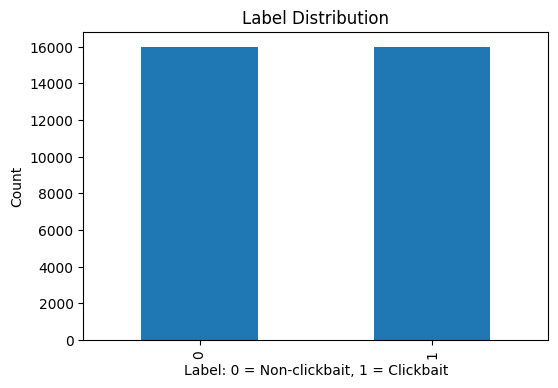

In [ ]:
df['clickbait'].value_counts().plot(kind='bar', figsize=(6,4))

plt.title("Label Distribution")
plt.xlabel("Label: 0 = Non-clickbait, 1 = Clickbait")
plt.ylabel("Count")
plt.show()

In [ ]:
df = df.dropna()
df = df.drop_duplicates()

df['headline'] = df['headline'].astype(str)

print(df.shape)

(32000, 2)


In [ ]:
!pip install wordcloud

In [ ]:
from wordcloud import WordCloud, STOPWORDS

custom_stopwords = STOPWORDS.union({

    "people",
    "person",
    "thing",
    "things",

    "time",
    "times",

    "know",
    "make",
    "made",

    "new",
    "best",
    "actually",

    "life",
    "love",

    "need",
    "real",

    "favorite",
    "way",
    "ways",

    "like",
    "just",

    "ll",

    "15","17","18","19",
    "21","22","23",
    "2015"
})

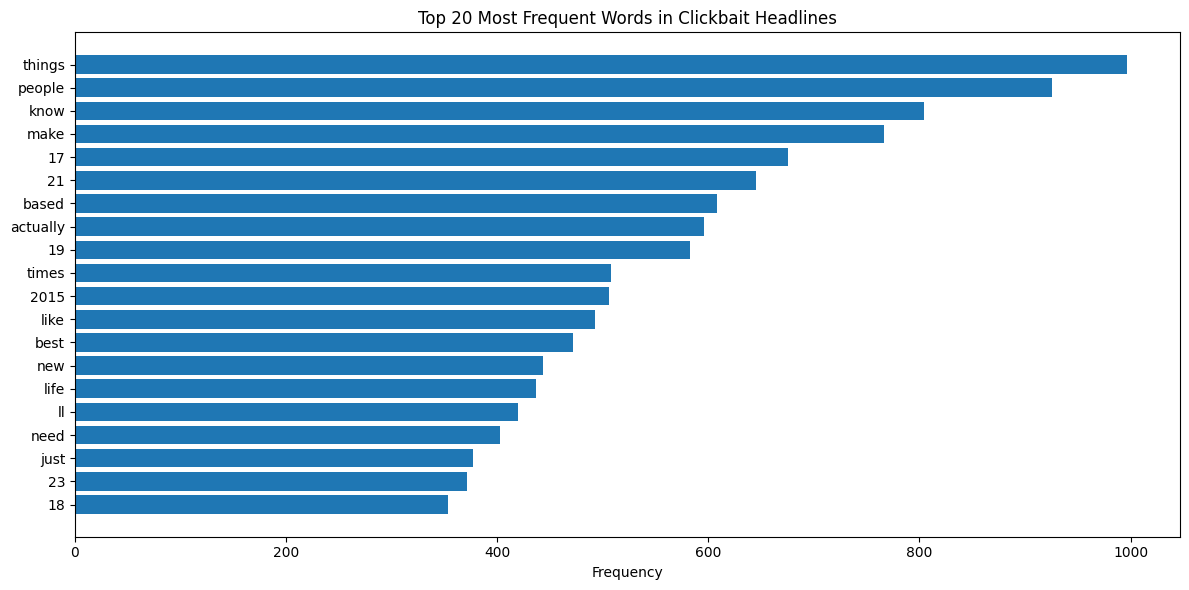

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt

vectorizer = CountVectorizer(
    stop_words='english',
    max_features=20
)

X = vectorizer.fit_transform(
    df[df["clickbait"] == 1]["headline"]
)

freq = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "Frequency": X.toarray().sum(axis=0)
})

freq = freq.sort_values(
    "Frequency",
    ascending=False
)

plt.figure(figsize=(12,6))

plt.barh(
    freq["Word"][::-1],
    freq["Frequency"][::-1]
)

plt.title("Top 20 Most Frequent Words in Clickbait Headlines")
plt.xlabel("Frequency")

plt.tight_layout()
plt.show()

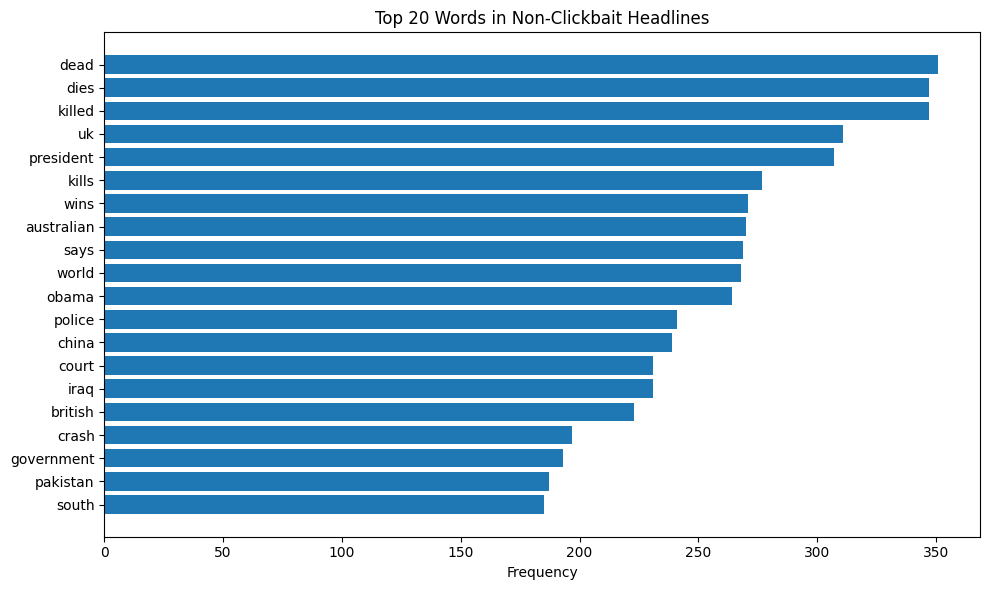

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
import pandas as pd
import matplotlib.pyplot as plt

vectorizer = CountVectorizer(
    stop_words=list(ENGLISH_STOP_WORDS.union({"new"})),
    max_features=20
)

X = vectorizer.fit_transform(
    df[df["clickbait"] == 0]["headline"]
)

freq = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "Frequency": X.toarray().sum(axis=0)
})

freq = freq.sort_values(
    "Frequency",
    ascending=False
)

plt.figure(figsize=(10,6))

plt.barh(
    freq["Word"][::-1],
    freq["Frequency"][::-1]
)

plt.title("Top 20 Words in Non-Clickbait Headlines")
plt.xlabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['clickbait']
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df['clickbait']
)

print("Train:", train_df.shape)
print("Valid:", valid_df.shape)
print("Test:", test_df.shape)

Train: (25600, 2)
Valid: (3200, 2)
Test: (3200, 2)


In [ ]:
overlap = set(train_df["headline"]) & set(test_df["headline"])

print("Overlap:", len(overlap))

Overlap: 0


In [ ]:
train_dataset = Dataset.from_pandas(train_df)
valid_dataset = Dataset.from_pandas(valid_df)
test_dataset = Dataset.from_pandas(test_df)

In [ ]:
model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
def tokenize_function(example):
    return tokenizer(
        example["text"],
        padding="max_length",
        truncation=True,
        max_length=64
    )

train_dataset = train_dataset.map(tokenize_function, batched=True)
valid_dataset = valid_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/25600 [00:00<?, ? examples/s]

Map:   0%|          | 0/3200 [00:00<?, ? examples/s]

Map:   0%|          | 0/3200 [00:00<?, ? examples/s]

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        preds,
        average="binary"
    )

    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [ ]:
training_args = TrainingArguments(
    output_dir="./distilbert_clickbait_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_dir="./logs",
    load_best_model_at_end=True,
    metric_for_best_model="f1"
)

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    compute_metrics=compute_metrics
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.052500,0.046162,0.984375,0.980173,0.988750,0.984443
2,0.019096,0.075865,0.986563,0.993659,0.979375,0.986465
3,0.003437,0.071010,0.987500,0.989950,0.985000,0.987469


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


TrainOutput(global_step=4800, training_loss=0.03139700292299191, metrics={'train_runtime': 471.0826, 'train_samples_per_second': 163.029, 'train_steps_per_second': 10.189, 'total_flos': 1271687027097600.0, 'train_loss': 0.03139700292299191, 'epoch': 3.0})

In [ ]:
test_results = trainer.evaluate(test_dataset)

print(test_results)

{'eval_loss': 0.057173434644937515, 'eval_accuracy': 0.99125, 'eval_precision': 0.9900249376558603, 'eval_recall': 0.9925, 'eval_f1': 0.9912609238451935, 'eval_runtime': 6.0887, 'eval_samples_per_second': 525.562, 'eval_steps_per_second': 32.848, 'epoch': 3.0}


In [ ]:
predictions = trainer.predict(test_dataset)

y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

print(classification_report(
    y_true,
    y_pred,
    target_names=["Non-clickbait", "Clickbait"]
))

               precision    recall  f1-score   support

Non-clickbait       0.99      0.99      0.99      1600
    Clickbait       0.99      0.99      0.99      1600

     accuracy                           0.99      3200
    macro avg       0.99      0.99      0.99      3200
 weighted avg       0.99      0.99      0.99      3200



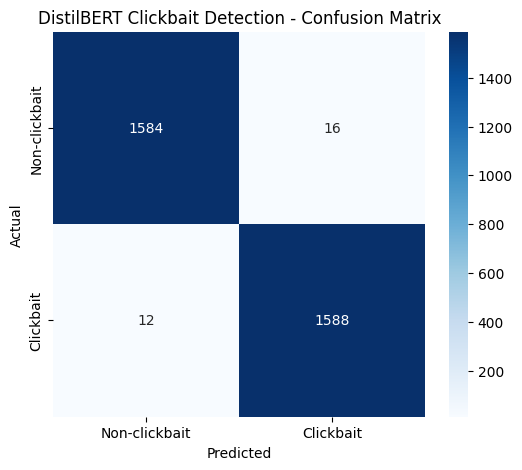

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-clickbait", "Clickbait"],
    yticklabels=["Non-clickbait", "Clickbait"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DistilBERT Clickbait Detection - Confusion Matrix")
plt.show()

In [ ]:
save_path = "/content/drive/MyDrive/NLP/distilbert_clickbait_model"

model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print("Model saved to:", save_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/drive/MyDrive/NLP/distilbert_clickbait_model


In [ ]:
def predict_clickbait(headline):
    inputs = tokenizer(
        headline,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=64
    )

    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    model.eval()

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1)
        pred = torch.argmax(probs, dim=1).item()

    label = "Clickbait" if pred == 1 else "Non-clickbait"
    confidence = probs[0][pred].item()

    return label, confidence

In [ ]:
headline = "You Won't Believe What This Man Found In His Backyard"

label, confidence = predict_clickbait(headline)

print("Headline:", headline)
print("Prediction:", label)
print("Confidence:", round(confidence * 100, 2), "%")

Headline: You Won't Believe What This Man Found In His Backyard
Prediction: Clickbait
Confidence: 100.0 %


In [ ]:
headline = "Government Announces New Education Policy For Public Schools"

label, confidence = predict_clickbait(headline)

print("Headline:", headline)
print("Prediction:", label)
print("Confidence:", round(confidence * 100, 2), "%")

Headline: Government Announces New Education Policy For Public Schools
Prediction: Non-clickbait
Confidence: 99.99 %


In [ ]:
!pip install lime -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
from lime.lime_text import LimeTextExplainer
import torch
import numpy as np

In [ ]:
class_names = ["Non-clickbait", "Clickbait"]

def predict_proba(texts):
    inputs = tokenizer(
        list(texts),
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=64
    )

    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    model.eval()

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1)

    return probs.detach().cpu().numpy()

In [ ]:
!pip install transformers-interpret -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.9/45.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 49.2 MB/s eta 0:00:00


In [ ]:
from transformers_interpret import SequenceClassificationExplainer
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
cls_explainer = SequenceClassificationExplainer(
    model,
    tokenizer
)

In [ ]:
headline = "You Will Not Believe What This Man Found In His Backyard"

word_attributions = cls_explainer(headline)

print("Predicted class:", cls_explainer.predicted_class_name)
print("Prediction score:", cls_explainer.pred_probs)

Predicted class: LABEL_1
Prediction score: tensor(1.0000, device='cuda:0')


In [ ]:
attr_df = pd.DataFrame(
    word_attributions,
    columns=["Token", "Attribution"]
)

attr_df

,Token,Attribution
0,[CLS],0.000000
1,you,0.570472
2,will,0.344758
3,not,0.363597
4,believe,-0.003308
5,what,0.407611
6,this,0.216462
7,man,0.164078
8,found,-0.090875
9,in,0.331565


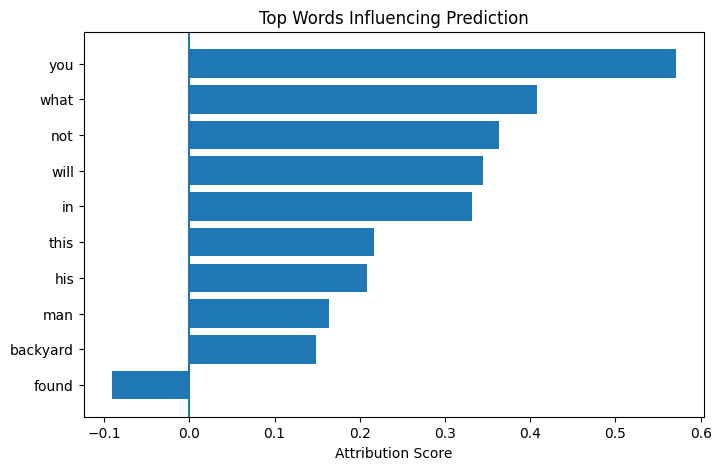

In [ ]:
attr_df["Abs_Attribution"] = attr_df["Attribution"].abs()

plot_df = attr_df.sort_values(
    by="Abs_Attribution",
    ascending=False
).head(10)

plot_df = plot_df.sort_values(
    by="Abs_Attribution",
    ascending=True
)

plt.figure(figsize=(8,5))

plt.barh(
    plot_df["Token"],
    plot_df["Attribution"]
)

plt.axvline(0)

plt.xlabel("Attribution Score")
plt.title("Top Words Influencing Prediction")

plt.show()

In [ ]:
headline = "Government Announces New Education Policy For Public Schools"

word_attributions = cls_explainer(headline)

print("Predicted class:", cls_explainer.predicted_class_name)
print("Prediction score:", cls_explainer.pred_probs)

attr_df = pd.DataFrame(
    word_attributions,
    columns=["Token", "Attribution"]
)

attr_df

Predicted class: LABEL_0
Prediction score: tensor(0.9999, device='cuda:0')


,Token,Attribution
0,[CLS],0.000000
1,government,0.436982
2,announces,0.231698
3,new,0.153780
4,education,0.355928
5,policy,0.595274
6,for,0.196880
7,public,0.454231
8,schools,0.074770
9,[SEP],0.000000


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/NLP/distilbert_clickbait_model"

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH
)

model.eval()

print("Model loaded successfully!")

Loading weights:   0%|          | 0/104 [00:01<?, ?it/s]

Model loaded successfully!
